# Balance estocástico: simulación y evaluación fuera de muestra

## Pregunta
¿Puede un remuestreo conjunto de cambios trimestrales de activos y pasivos proporcionar intervalos útiles para el cociente patrimonio/activos del siguiente trimestre? Se analizan estados observados de un banco de EE. UU. y escenarios construidos con su historia; no son proyecciones de la entidad ni un ALM de flujos y vencimientos. Cada escenario conserva la diferencia residual entre activos menos pasivos y patrimonio reportado en su fecha inicial.

## Datos y definiciones

Fuente: [FDIC BankFind API](https://api.fdic.gov/banks/docs/), institución JPMorgan Chase Bank, N.A. (CERT 628), corte público descargado 2026-11-12. Extracto congelado JSON, 50 trimestres más recientes hasta 2026-06-30; montos en miles USD. `ASSET` activos, `LIAB` pasivos, `EQ` patrimonio, `DEP` depósitos, `LNLSNET` préstamos netos y `SC` valores. [FDIC Financial Reporting](https://banks.data.fdic.gov/bankfind-suite/financialreporting/report) ofrece datos trimestrales. El archivo y su huella se guardan junto al notebook de balance estocástico.

El cociente patrimonio/activos es una medida contable simple, no capital regulatorio sobre activos ponderados. Modelamos las tasas de crecimiento de activos y pasivos por pares para conservar dependencia contemporánea. La periodicidad trimestral oculta movimientos intratrimestre.

In [1]:
from pathlib import Path
import json,hashlib,numpy as np,pandas as pd,matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
p=root/'03-financial-risk/05-enterprise-risk-advisory/02-capital-alm/stochastic-balance-sheet-alm/data/fdic_cert628_2026-11-12.json'
raw=json.loads(p.read_text());df=pd.DataFrame([item['data'] for item in raw['data']]);df['fecha']=pd.to_datetime(df.REPDTE,format='%Y%m%d');df=df.sort_values('fecha').reset_index(drop=True)
for c in ['ASSET','LIAB','EQ','DEP','LNLSNET','SC']:df[c]=pd.to_numeric(df[c],errors='coerce')
assert len(df)==50 and not df.fecha.duplicated().any() and df[['ASSET','LIAB','EQ','DEP']].notna().all().all()
assert (df[['ASSET','LIAB','DEP']]>0).all().all()
print('SHA-256:',hashlib.sha256(p.read_bytes()).hexdigest(),'| periodos:',len(df),'| corte:',df.fecha.min().date(),df.fecha.max().date())
print('Índice de origen:',raw['meta']['index']['name']); print('Máx. diferencia activos − pasivos − patrimonio (miles USD):', (df.ASSET-df.LIAB-df.EQ).abs().max())
df['ratio_capital']=df.EQ/df.ASSET;df['ratio_depositos']=df.DEP/df.ASSET

SHA-256: 307771a9e02673a881ad7b4112de81ea9cb2f69c8db3e954df9beffe0036a337 | periodos: 50 | corte: 2014-03-31 2026-06-30
Índice de origen: risview_20260819185831
Máx. diferencia activos − pasivos − patrimonio (miles USD): 266000


## Calidad y dinámica observada
La diferencia entre activos menos pasivos y patrimonio reportado se comprueba sin imputaciones. Esa diferencia no es siempre cero; se mantiene constante en el punto de partida de cada escenario, sin atribuirla a un componente concreto. Se identifican periodos consecutivos antes de calcular cambios; una adquisición, revisión o cambio contable puede producir saltos no comparables. En este ejercicio no se ajustan fusiones ni cambios estructurales.

In [2]:
assert df.fecha.dt.to_period('Q').diff().dropna().map(lambda x:x.n==1).all(), 'Faltan trimestres consecutivos'
df['crec_activo']=df.ASSET.pct_change(fill_method=None);df['crec_pasivo']=df.LIAB.pct_change(fill_method=None)
df[['fecha','ASSET','LIAB','EQ','DEP','ratio_capital']].tail()

,fecha,ASSET,LIAB,EQ,DEP,ratio_capital
45,2025-06-30,3788551000,3465741000,322777000,2669161000,0.085198
46,2025-09-30,3813431000,3481445000,331953000,2649438000,0.087048
47,2025-12-31,3752662000,3416692000,335936000,2697842000,0.089519
48,2026-03-31,4016571000,3680610000,335931000,2787994000,0.083636
49,2026-06-30,4091315000,3749705000,341580000,2820284000,0.083489


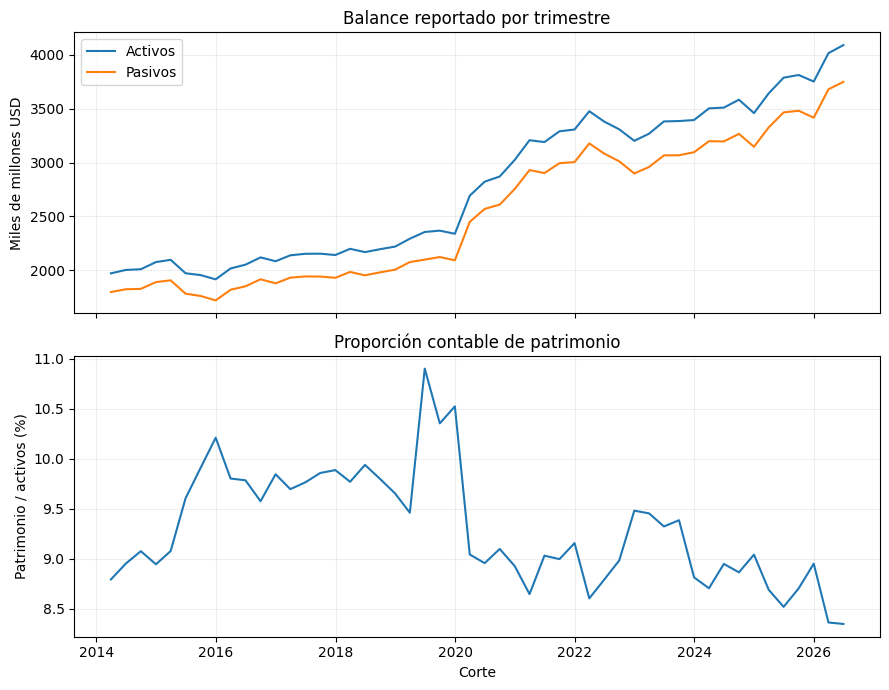

In [3]:
fig,ax=plt.subplots(2,1,figsize=(9,7),sharex=True);ax[0].plot(df.fecha,df.ASSET/1e6,label='Activos');ax[0].plot(df.fecha,df.LIAB/1e6,label='Pasivos');ax[0].set(ylabel='Miles de millones USD',title='Balance reportado por trimestre');ax[0].legend();ax[1].plot(df.fecha,df.ratio_capital*100);ax[1].set(ylabel='Patrimonio / activos (%)',xlabel='Corte',title='Proporción contable de patrimonio');[x.grid(alpha=.2) for x in ax];plt.tight_layout();plt.show()

## Modelo y controles de fuga temporal
Para cada pronóstico de un trimestre entre 2025 y 2026-06, la distribución de pares de crecimiento se estima con datos disponibles hasta el trimestre anterior. Cada par se remuestrea con reemplazo; se calcula patrimonio como activo simulado menos pasivo simulado y menos la diferencia residual observada al inicio del escenario. El intervalo central 90 % de las simulaciones se compara con el resultado observado. La línea base conserva el último cociente observado. Se exige al menos 16 cambios previos y no se limita artificialmente patrimonio negativo. Se excluyen cambios mayores o iguales al 100 % a la baja por inviabilidad de activos o pasivos no positivos. Semilla fija; 5.000 escenarios por origen.

In [4]:
rng=np.random.default_rng(628);rows=[]
for i in range(1,len(df)):
    target=df.iloc[i];previous=df.iloc[i-1]
    if target.fecha < pd.Timestamp('2025-01-01'):continue
    hist=df.iloc[1:i][['crec_activo','crec_pasivo']].dropna();hist=hist[(hist.crec_activo>-1)&(hist.crec_pasivo>-1)]
    if len(hist)<16:continue
    draws=hist.to_numpy()[rng.integers(0,len(hist),5000)]
    aset=previous.ASSET*(1+draws[:,0]);liab=previous.LIAB*(1+draws[:,1]);residual=previous.ASSET-previous.LIAB-previous.EQ;rat=(aset-liab-residual)/aset
    lo,med,hi=np.quantile(rat,[.05,.5,.95]);actual=float(target.ratio_capital)
    rows.append({'fecha':target.fecha,'train_n':len(hist),'observado':actual,'base_ultimo':previous.ratio_capital,'mediana_simulada':med,'limite_5':lo,'limite_95':hi,'dentro_90':bool(lo<=actual<=hi),'escenarios_capital_negativo':float((rat<0).mean())})
res=pd.DataFrame(rows).set_index('fecha');assert len(res)>0 and res[['limite_5','mediana_simulada','limite_95']].notna().all().all();res.round(4)

,train_n,observado,base_ultimo,mediana_simulada,limite_5,limite_95,dentro_90,escenarios_capital_negativo
fecha,,,,,,,,
2025-03-31,43,0.0869,0.0904,0.0907,0.0848,0.0954,True,0.0
2025-06-30,44,0.0852,0.0869,0.0867,0.0813,0.0919,True,0.0
2025-09-30,45,0.0870,0.0852,0.0850,0.0796,0.0902,True,0.0
2025-12-31,46,0.0895,0.0870,0.0869,0.0815,0.0920,True,0.0
2026-03-31,47,0.0836,0.0895,0.0898,0.0839,0.0945,False,0.0
2026-06-30,48,0.0835,0.0836,0.0839,0.0779,0.0886,True,0.0


In [5]:
mae_base=(res.observado-res.base_ultimo).abs().mean()*100;mae_modelo=(res.observado-res.mediana_simulada).abs().mean()*100
print('Pronósticos:',len(res),'| Cobertura de intervalos 90 %:',round(100*res.dentro_90.mean(),1),'%')
print('MAE en puntos porcentuales — último observado:',round(mae_base,3),'| mediana bootstrap:',round(mae_modelo,3))
print('Los resultados son una comparación descriptiva de pocos trimestres, no una prueba de superioridad.')

Pronósticos: 6 | Cobertura de intervalos 90 %: 83.3 %
MAE en puntos porcentuales — último observado: 0.26 | mediana bootstrap: 0.277
Los resultados son una comparación descriptiva de pocos trimestres, no una prueba de superioridad.


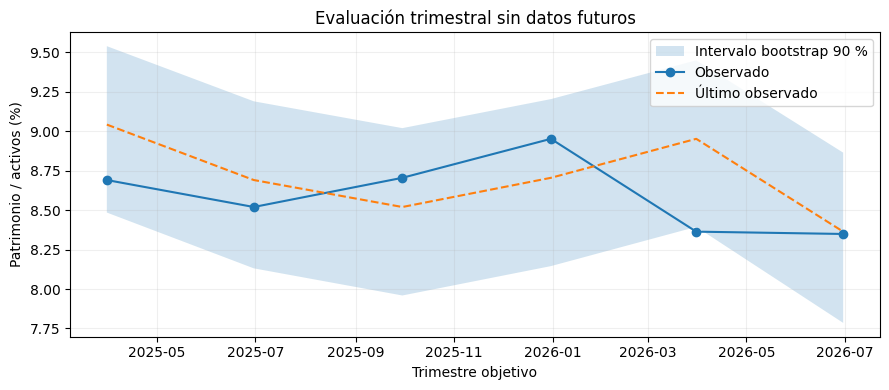

In [6]:
fig,ax=plt.subplots(figsize=(9,4));ax.fill_between(res.index,res.limite_5*100,res.limite_95*100,alpha=.2,label='Intervalo bootstrap 90 %');ax.plot(res.index,res.observado*100,'o-',label='Observado');ax.plot(res.index,res.base_ultimo*100,'--',label='Último observado');ax.set(title='Evaluación trimestral sin datos futuros',xlabel='Trimestre objetivo',ylabel='Patrimonio / activos (%)');ax.grid(alpha=.2);ax.legend();plt.tight_layout();plt.show()

## Interpretación y límites
La frecuencia simulada de patrimonio negativo depende por completo de los saltos históricos remuestreados; no es probabilidad de quiebra. La evaluación tiene pocos trimestres y no ajusta fusiones ni cambios contables. Faltan vencimientos, tasas, comportamiento de depósitos, valoraciones, liquidez y escenarios exógenos. Para un ALM institucional se requiere un balance granular, controles, validación independiente y comparación con procesos reales. [BCBS: principios de gestión de liquidez](https://www.bis.org/publ/bcbs144.htm). La diferencia residual contable se mantiene constante por escenario; no se han reconciliado ni modelado sus componentes.